# [GSE220059](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE220059)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-09-29
> - Modified: 2025-01-12

> **Notes:**
> - Potential sample annotation inconsistency was observed in GSE220059, as the polysome-seq samples cluster opposite to their reported group labels.

# 1. Experimental Design

> RNA binding protein PRRC2B mediates translation of specific proteins and regulates cell cycle progression.
> - Feng Jiang, Omar M Hedaya, EngSoon Khor, Jiangbin Wu, Matthew Auguste, Peng Yao, RNA binding protein PRRC2B mediates translation of specific mRNAs and regulates cell cycle progression, Nucleic Acids Research, Volume 51, Issue 11, 23 June 2023, Pages 5831–5846, https://doi.org/10.1093/nar/gkad322.
> - total RNA-seq & Polysome-seq
> - Illumina NovaSeq 6000, PE150
> - GRCh38

| Sample | Organism | Cell | Source | Treatment | Library | Replicate |
| - | - | - | - | - | - | - |
| Control | Homo sapiens | HEK293T | Human embryonic kidney | Control shRNA | Total RNA | rep1~3 |
| shPRRC2B | Homo sapiens | HEK293T | Human embryonic kidney | shPRRC2B | Total RNA | rep1~3 |
| Control | Homo sapiens | HEK293T | Human embryonic kidney | Control shRNA | Polysome RNA | rep1~3 |
| shPRRC2B | Homo sapiens | HEK293T | Human embryonic kidney | shPRRC2B | Polysome RNA | rep1~3 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [ ]:
data_dir <- "~/dataset_1/bulk_omics/polysomeseq_Hs_HEK293T_PRRC2B_GSE220059/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 20508    20

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("HEK293T"))) |>
    separate(
        col = sample, into = c("Cell", "Group", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_", "", sample),
        Group = factor(Group, levels = c("Control", "shPRRC2B")), 
        Fraction = recode(Fraction, "total" = "Total", "polysome" = "Polysome") |>
            factor(levels = c("Total", "Polysome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Group,Fraction,Replicate
,<chr>,<fct>,<fct>,<fct>
Control_total_rep1,HEK293T,Control,Total,rep1
Control_total_rep2,HEK293T,Control,Total,rep2
Control_total_rep3,HEK293T,Control,Total,rep3
Control_polysome_rep1,HEK293T,Control,Polysome,rep1
Control_polysome_rep2,HEK293T,Control,Polysome,rep2
Control_polysome_rep3,HEK293T,Control,Polysome,rep3
shPRRC2B_total_rep1,HEK293T,shPRRC2B,Total,rep1
shPRRC2B_total_rep2,HEK293T,shPRRC2B,Total,rep2
shPRRC2B_total_rep3,HEK293T,shPRRC2B,Total,rep3


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("HEK293T")) |>
    rename_with(~ sub("^[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group * Fraction)

class: DESeqDataSet 
dim: 20508 12 
metadata(1): version
assays(1): counts
rownames(20508): ENSG00000186092.7 ENSG00000284733.2 ...
  ENSG00000198695.2 ENSG00000198727.2
rowData names(3): symbol type basepairs
colnames(12): Control_total_rep1 Control_total_rep2 ...
  shPRRC2B_polysome_rep2 shPRRC2B_polysome_rep3
colData names(4): Cell Group Fraction Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE) |>
    str_subset(pattern = "HEK293T")

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Group", "Fraction", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sampleName = sub("^[^_]+_", "", sampleName),
        Group = factor(Group, levels = c("Control", "shPRRC2B")), 
        Fraction = recode(Fraction, "total" = "Total", "polysome" = "Polysome") |>
            factor(levels = c("Total", "Polysome")),
        Replicate = factor(Replicate)) |> 
    arrange(Group, Fraction, Replicate) |>
    select("sampleName", "fileName", "Cell", "Group", "Fraction", "Replicate") |>
    as.data.frame()

In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group * Fraction,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 20508 12 
metadata(1): version
assays(1): counts
rownames(20508): ENSG00000000003.16 ENSG00000000005.6 ...
  ENSG00000310562.1 ENSG00000310576.1
rowData names(0):
colnames(12): Control_total_rep1 Control_total_rep2 ...
  shPRRC2B_polysome_rep2 shPRRC2B_polysome_rep3
colData names(4): Cell Group Fraction Replicate

## 2). Object Construction

In [11]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 20508 12 
metadata(0):
assays(1): counts
rownames(20508): ENSG00000186092.7 ENSG00000284733.2 ...
  ENSG00000198695.2 ENSG00000198727.2
rowData names(3): symbol type basepairs
colnames(12): Control_total_rep1 Control_total_rep2 ...
  shPRRC2B_polysome_rep2 shPRRC2B_polysome_rep3
colData names(6): sampleName fileName ... Fraction Replicate

In [12]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group * Fraction)

dds

class: DESeqDataSet 
dim: 20508 12 
metadata(1): version
assays(1): counts
rownames(20508): ENSG00000186092.7 ENSG00000284733.2 ...
  ENSG00000198695.2 ENSG00000198727.2
rowData names(3): symbol type basepairs
colnames(12): Control_total_rep1 Control_total_rep2 ...
  shPRRC2B_polysome_rep2 shPRRC2B_polysome_rep3
colData names(6): sampleName fileName ... Fraction Replicate

In [13]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [14]:
keep <- rowSums(assay(eSet) >= 10) >= 3
# keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 13970 
 Remove: 6538 
 Retention rate: 68.12 %


In [15]:
design <- model.matrix(~ Group * Fraction, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 13995 
 Remove: 6513 
 Retention rate: 68.24 %


# 3. Normalization

In [16]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [17]:
dds <- estimateSizeFactors(dds)
# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)

In [18]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [19]:
design <- model.matrix(~ group + Fraction, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [20]:
rld <- rlog(dds, blind = FALSE)

In [21]:
suppressPackageStartupMessages(library(vsn))

In [22]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [23]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


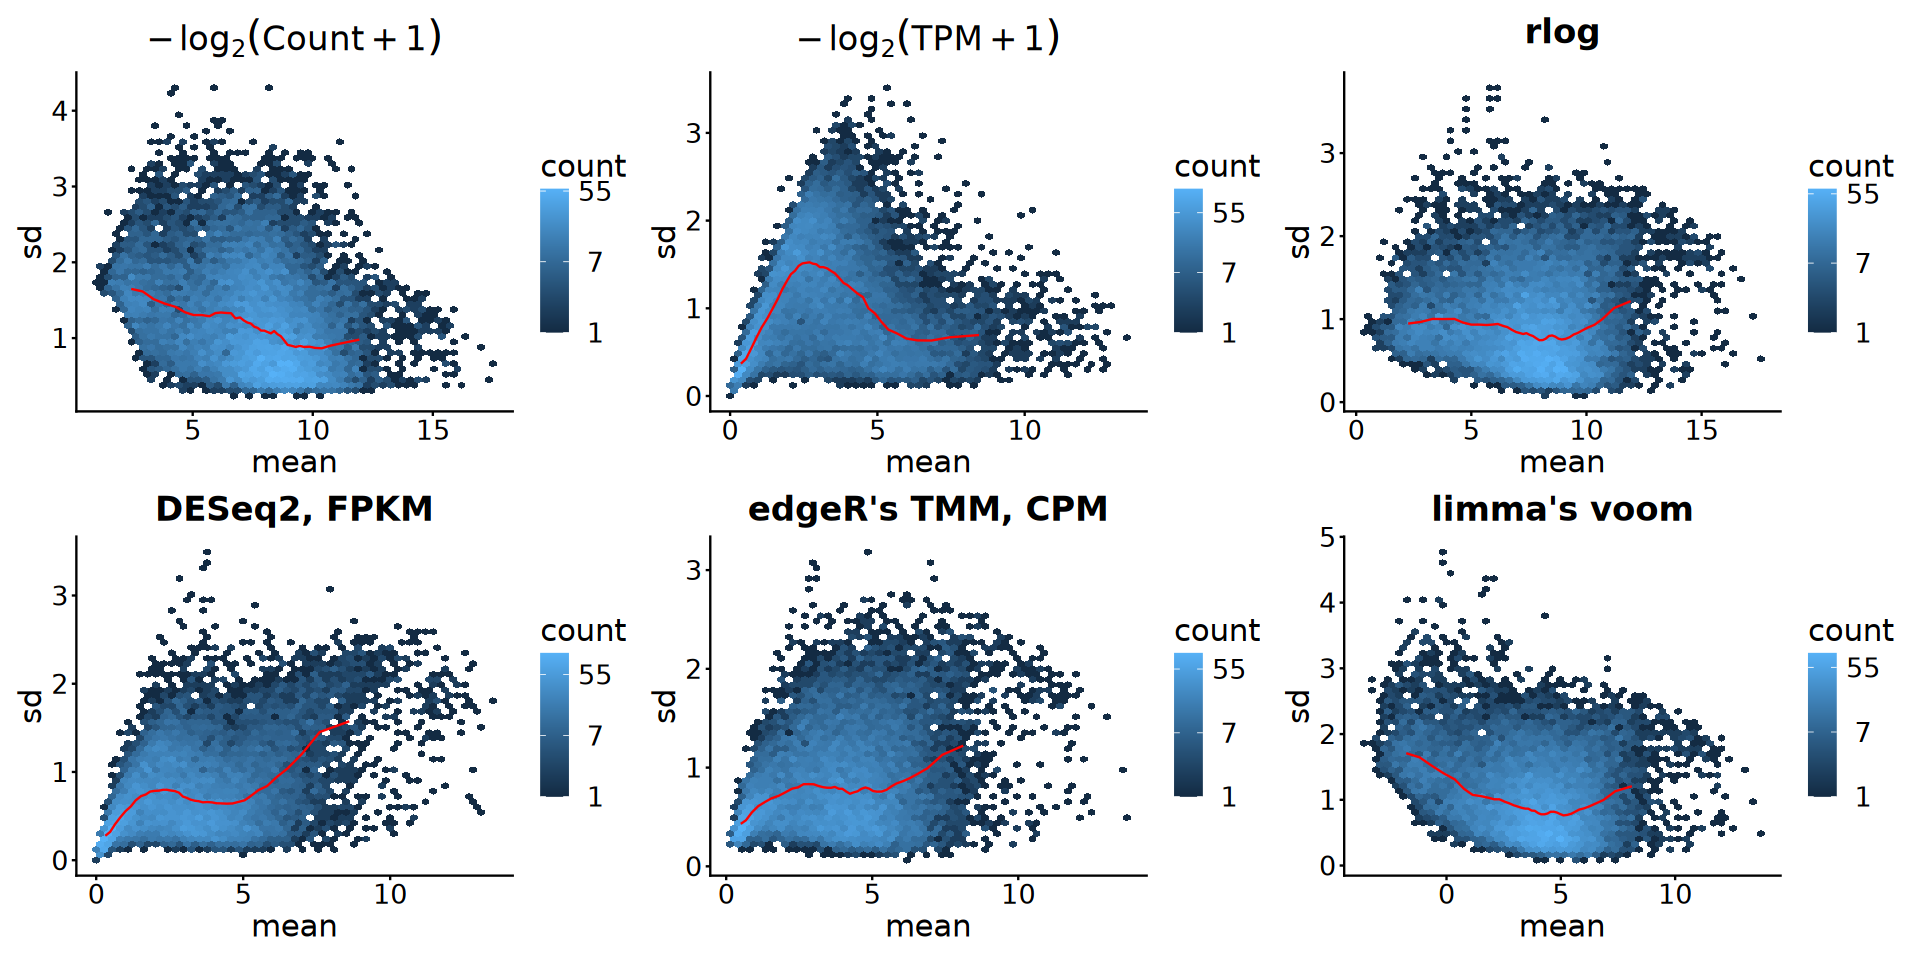

In [24]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [25]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [26]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Fraction, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

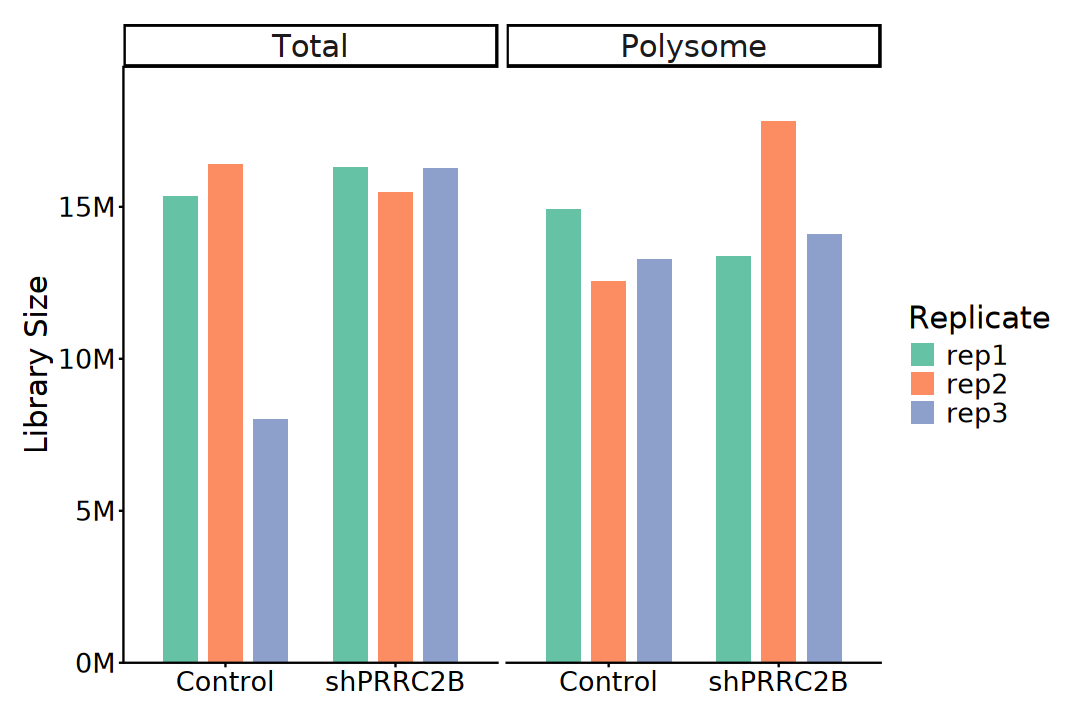

In [27]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Replicate)) +
    geom_bar(
        aes(fill = Replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    facet_wrap(~ Fraction, nrow = 1) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [28]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 1000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [29]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [30]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [31]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Fraction", "Replicate"), 
    ntop = 1000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=1000 top features by variance



In [32]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 2, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [33]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [34]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 2, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

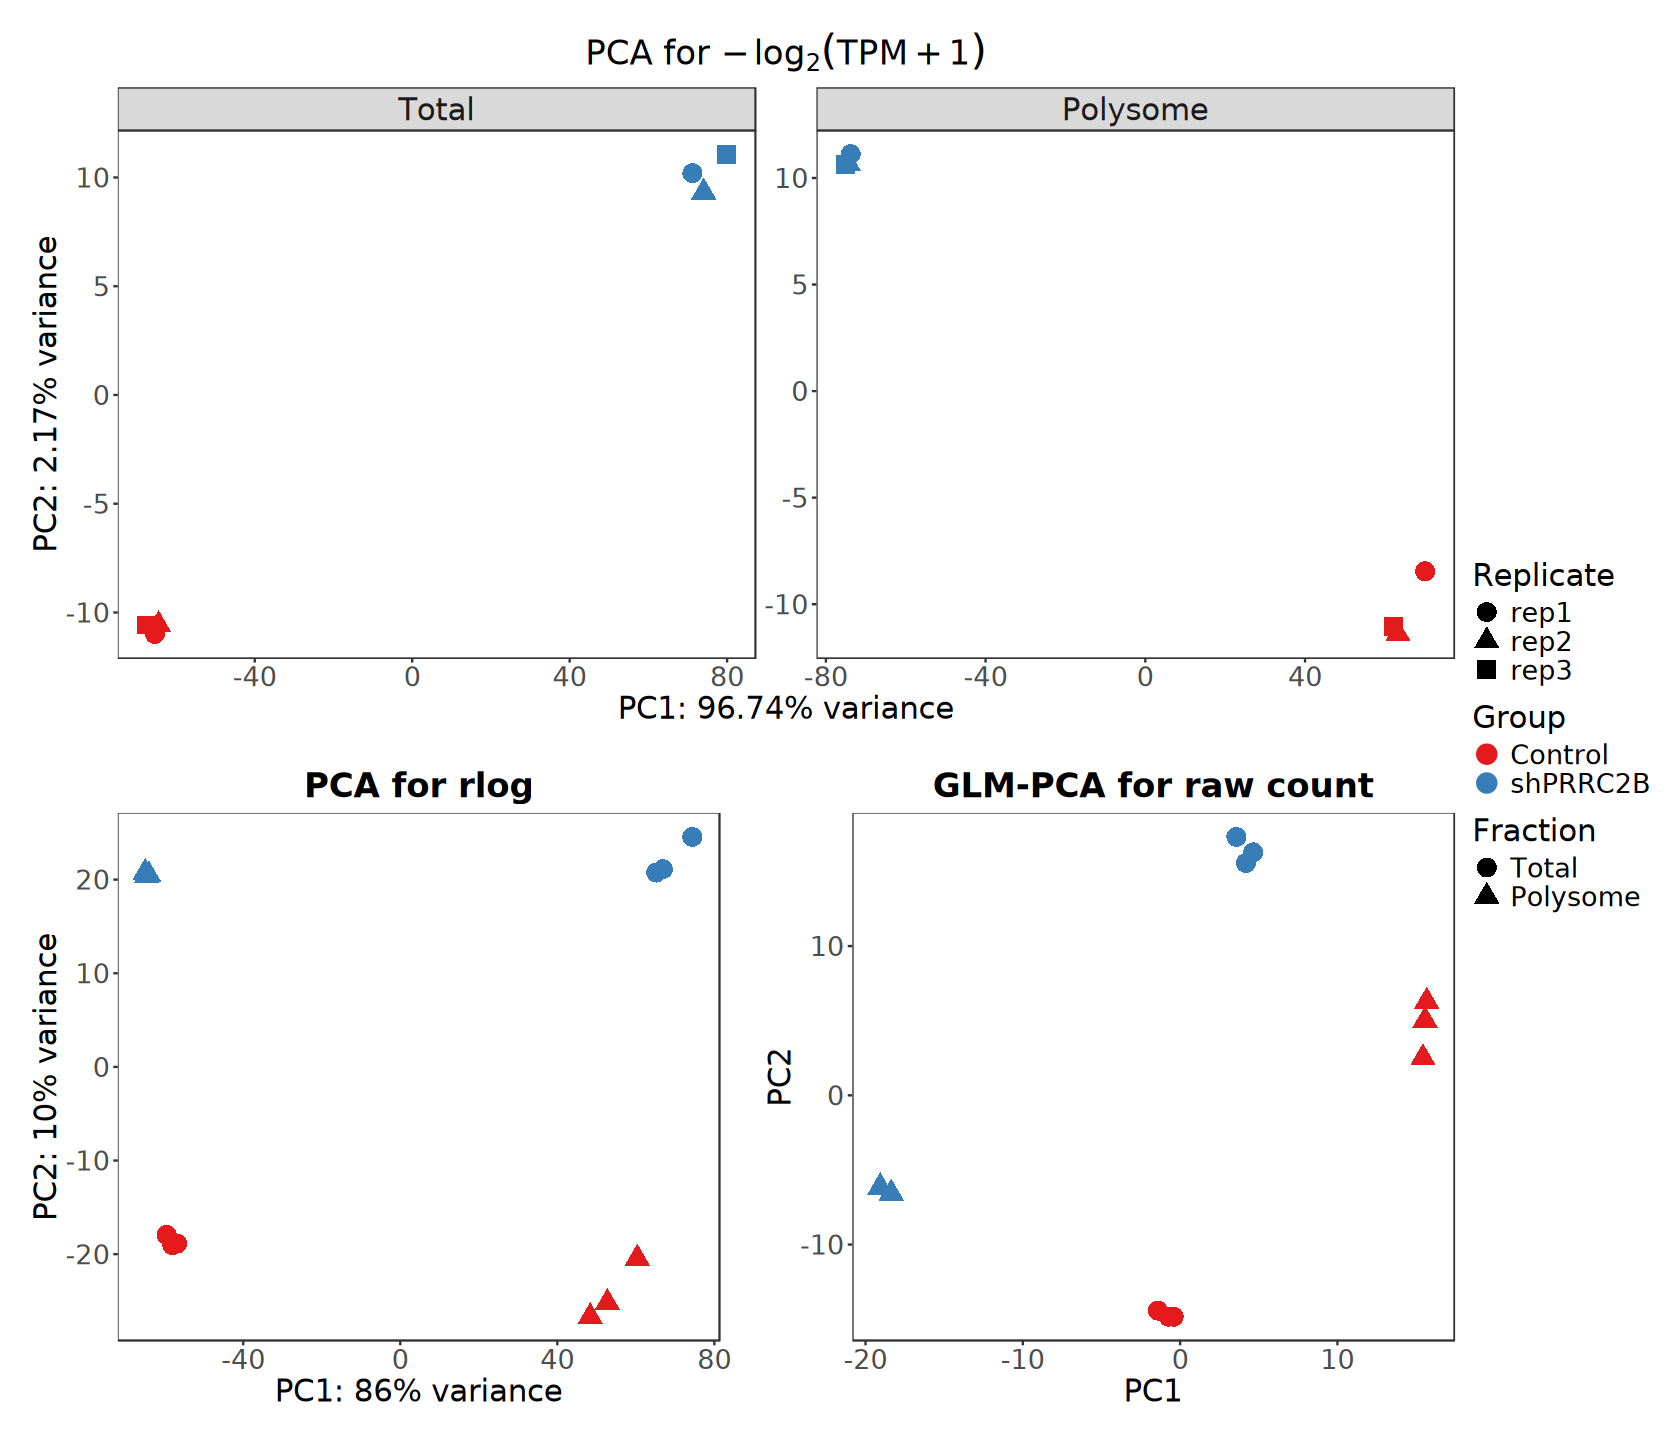

In [35]:
options(repr.plot.width = 14, repr.plot.height = 12)

p1 / (p2 + p3) + plot_layout(nrow = 2, guides = "collect")

## 3). MDS

> Multidimensional scaling

In [36]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

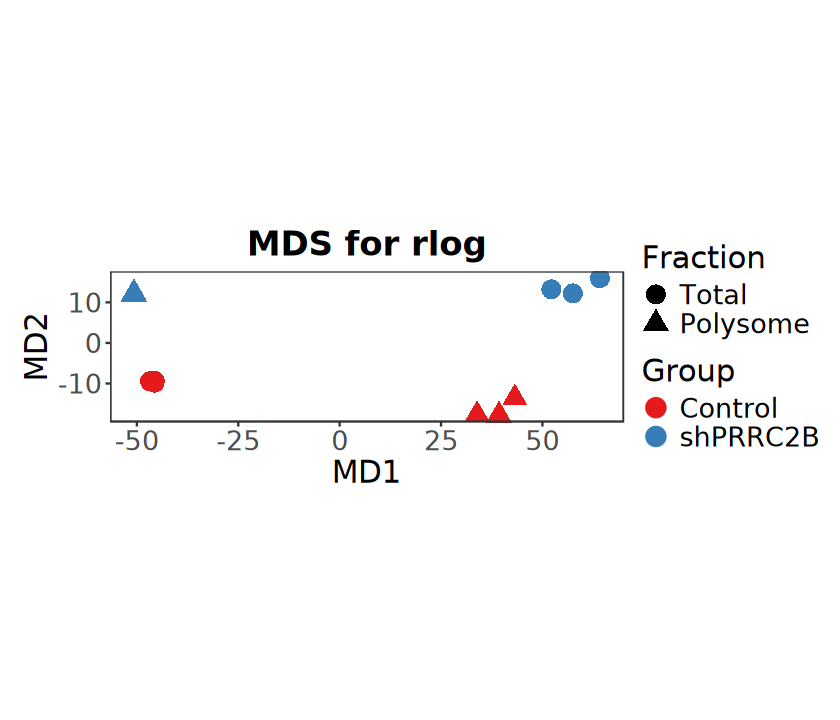

In [37]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Fraction), size = 5) +
    # facet_wrap( ~ Fraction, nrow = 1) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [38]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

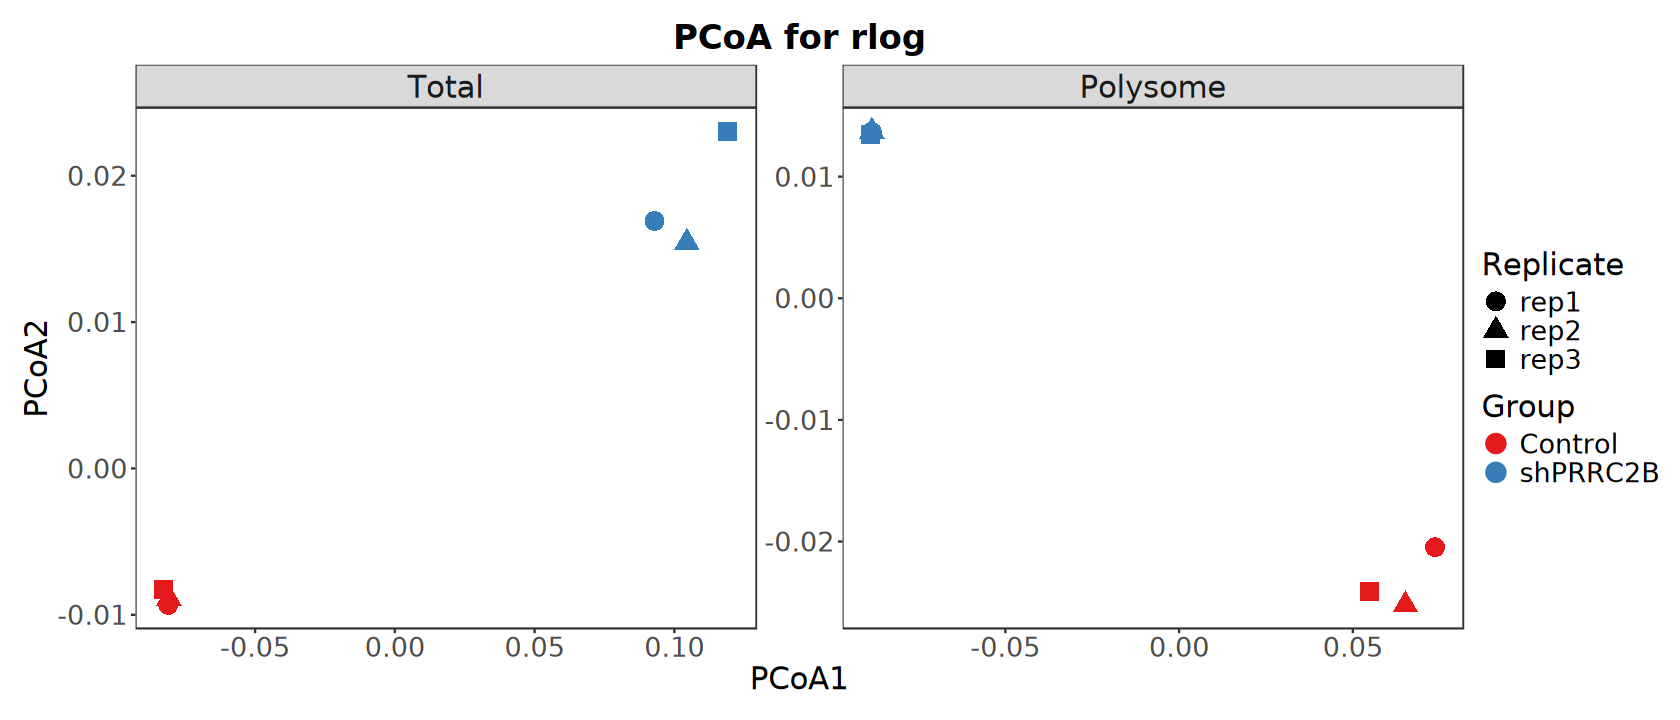

In [39]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    facet_wrap( ~ Fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [40]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Fraction, Group)

In [41]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
fraction_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(eSet$Fraction)),
    levels(eSet$Fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Fraction = fraction_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [42]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

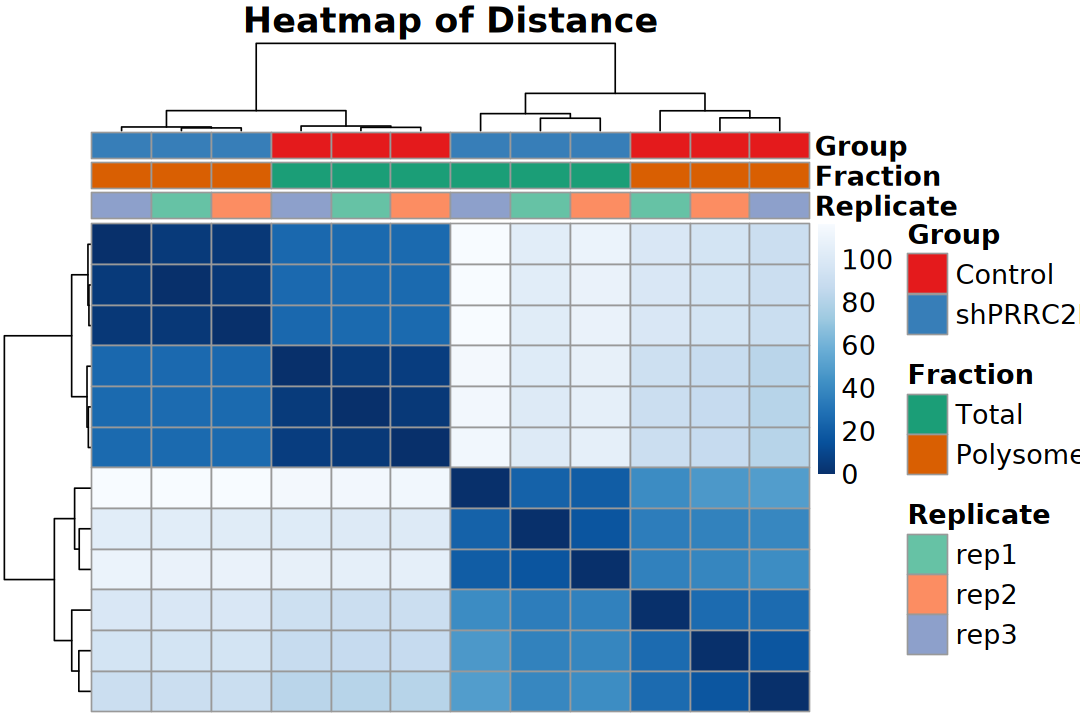

In [43]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [44]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

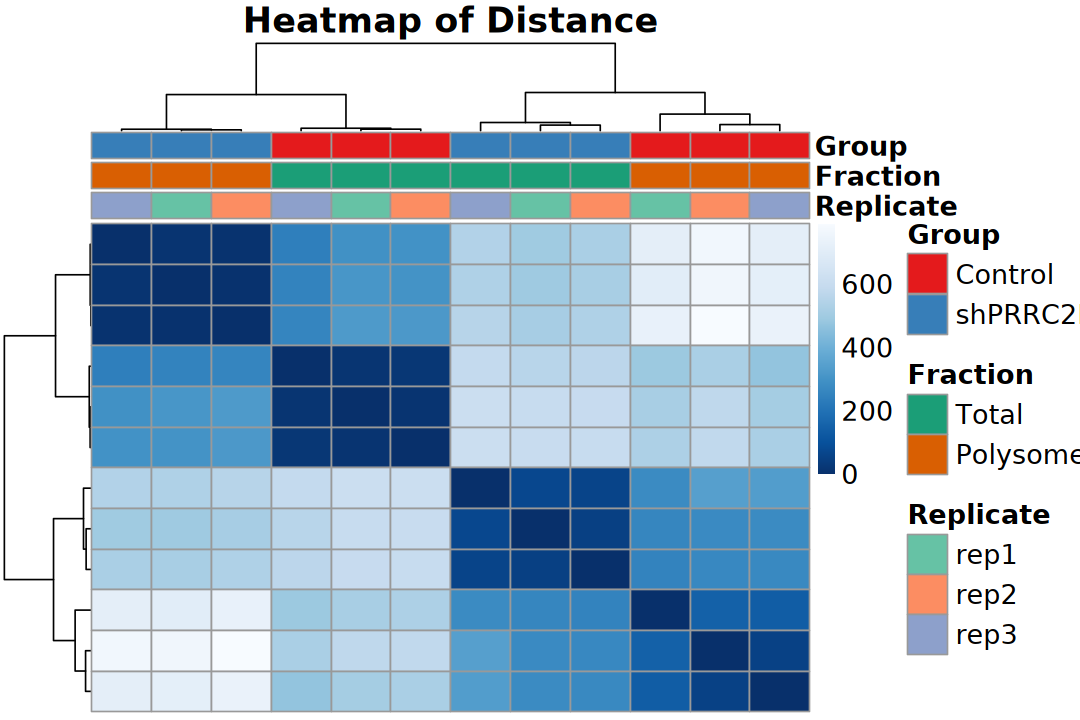

In [45]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [46]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

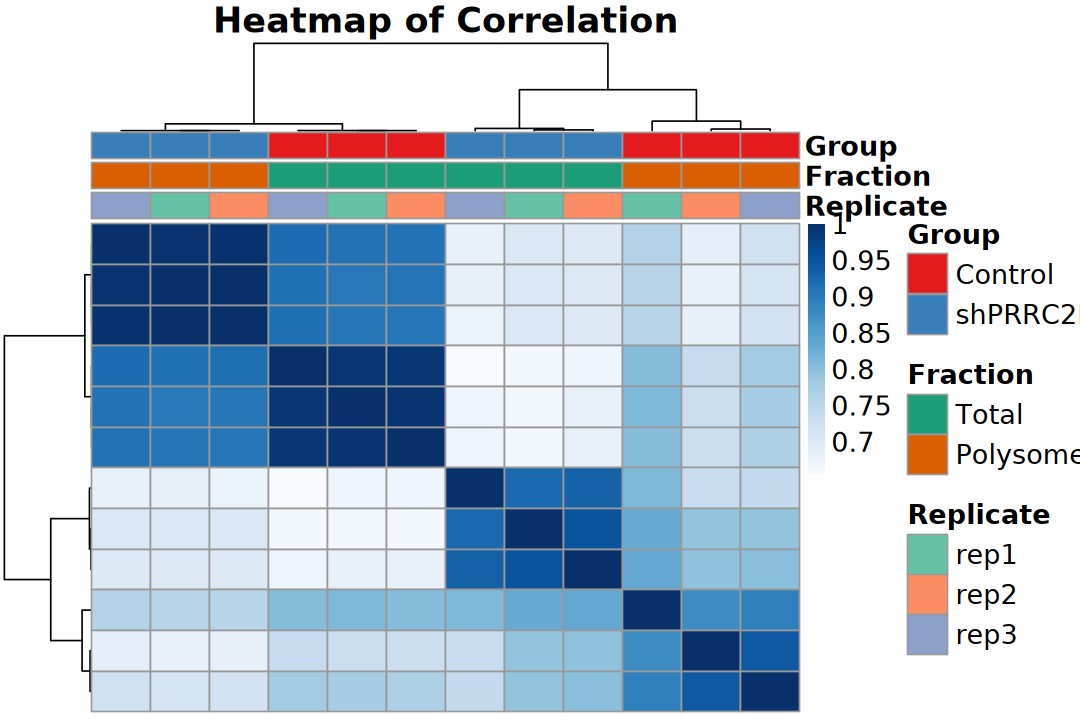

In [47]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

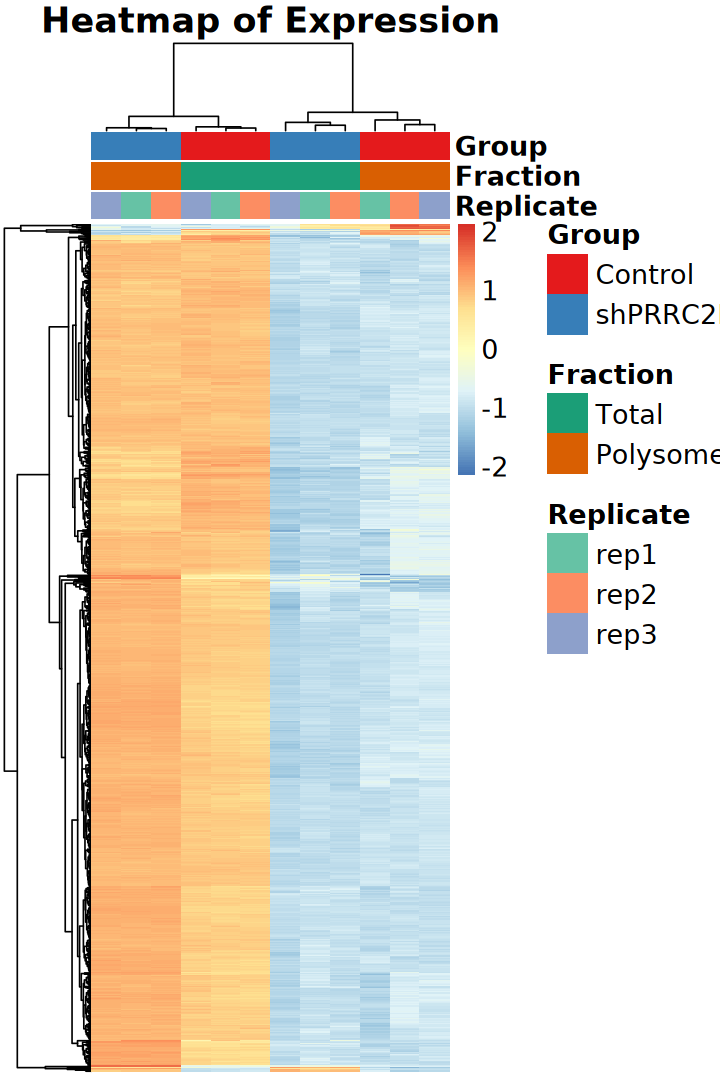

In [48]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

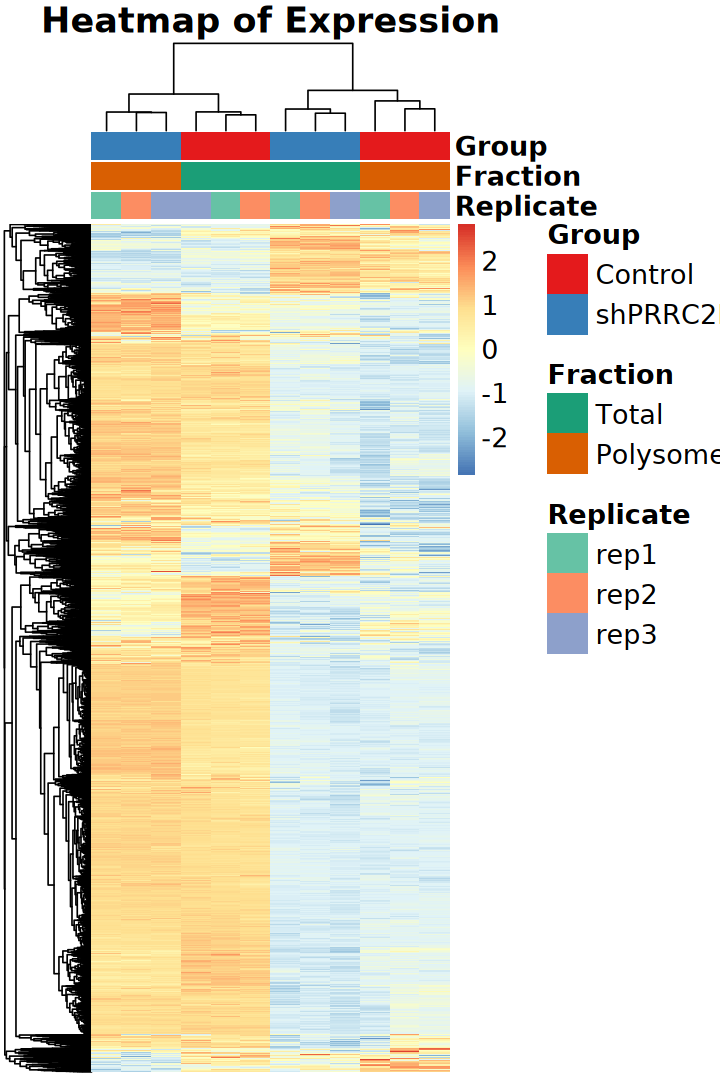

In [49]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat, scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

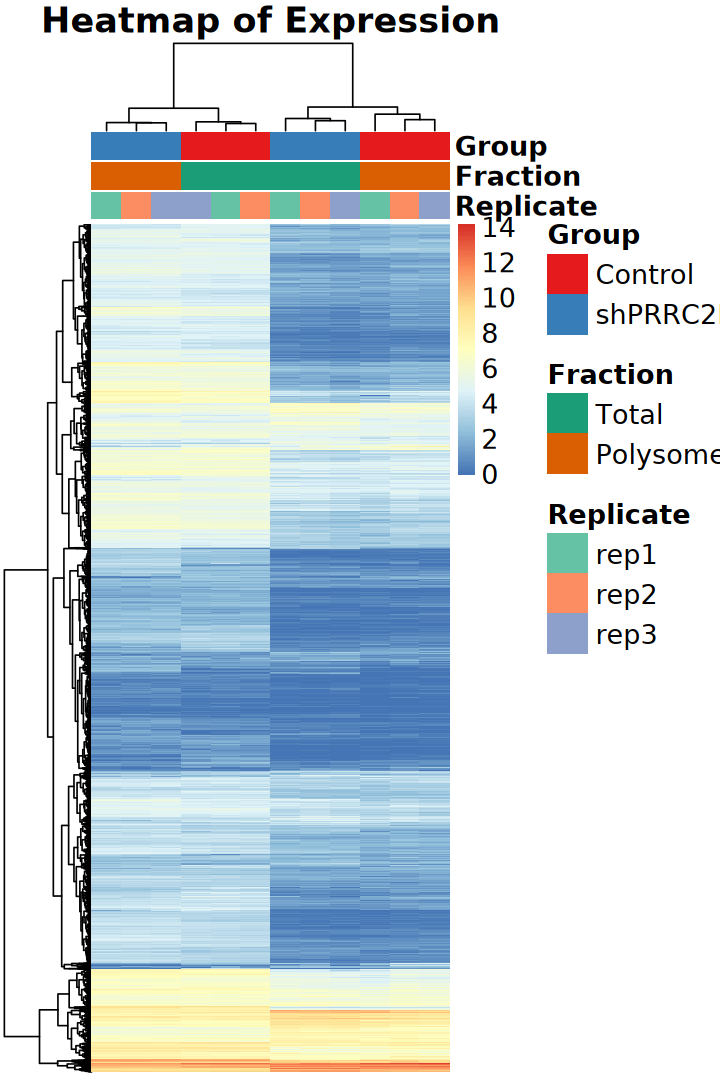

In [50]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat,
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# GEO Dataset

In [51]:
expr_mat <- file.path(data_dir, "../00_geo/GSE220058_counts_matrix.csv.gz") |> 
    read_csv(show_col_types = FALSE) |>
    dplyr::select(where(~ !is.logical(.x))) |>
    dplyr::rename(gene = 1) |>
    column_to_rownames("gene") |>
    as.matrix()

head(expr_mat)

New names:
• `` -> `...1`
• `` -> `...14`
• `` -> `...15`
• `` -> `...16`
• `` -> `...17`
• `` -> `...18`


,shPRRC2B polysome bio rep 1,shPRRC2B total bio rep 2,shCtrl polysome bio rep 1,shCtrl polysome bio rep 2,shCtrl polysome bio rep 3,shPRRC2B polysome bio rep 2,shPRRC2B polysome bio rep 3,shCtrl total bio rep 1,shCtrl total bio rep 2,shCtrl total bio rep 3,shPRRC2B total bio rep 3,shPRRC2B total bio rep 1
5_8S_rRNA,0,0,0,0,0,0,0,0,0,0,0,0
5S_rRNA,1,1,0,0,0,0,0,2,0,0,2,0
7SK,0,0,0,0,0,0,0,1,1,1,0,0
A1BG,7,11,16,3,0,1,11,25,27,19,9,17
A1BG-AS1,93,70,75,49,64,74,98,106,91,67,60,60
A1CF,0,6,4,0,0,2,1,4,6,1,8,8


In [52]:
expr_coldata <- tibble(sample = colnames(expr_mat)) |>
    mutate(
        condition = if_else(
            str_detect(sample, "^shPRRC2B"), "shPRRC2B", "shCtrl") |> 
            factor(levels = c("shCtrl", "shPRRC2B")),
        fraction  = if_else(
            str_detect(sample, "polysome"), "Polysome", "Total") |> 
            factor(levels = c("Total", "Polysome")),
        replicate = str_extract(sample, "(?<=rep )\\d+") |> factor()) |>
    column_to_rownames("sample") |>
    arrange(condition, fraction, replicate)

expr_coldata

,condition,fraction,replicate
,<fct>,<fct>,<fct>
shCtrl total bio rep 1,shCtrl,Total,1
shCtrl total bio rep 2,shCtrl,Total,2
shCtrl total bio rep 3,shCtrl,Total,3
shCtrl polysome bio rep 1,shCtrl,Polysome,1
shCtrl polysome bio rep 2,shCtrl,Polysome,2
shCtrl polysome bio rep 3,shCtrl,Polysome,3
shPRRC2B total bio rep 1,shPRRC2B,Total,1
shPRRC2B total bio rep 2,shPRRC2B,Total,2
shPRRC2B total bio rep 3,shPRRC2B,Total,3


In [53]:
dds_tmp <- DESeqDataSetFromMatrix(
    countData = expr_mat[, rownames(expr_coldata)], 
    colData = expr_coldata, 
    design = ~ condition * fraction)

dds_tmp

converting counts to integer mode



class: DESeqDataSet 
dim: 59385 12 
metadata(1): version
assays(1): counts
rownames(59385): 5_8S_rRNA 5S_rRNA ... ZZEF1 ZZZ3
rowData names(0):
colnames(12): shCtrl total bio rep 1 shCtrl total bio rep 2 ...
  shPRRC2B polysome bio rep 2 shPRRC2B polysome bio rep 3
colData names(3): condition fraction replicate

In [54]:
keep <- rowSums(counts(dds_tmp) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dds_tmp <- dds_tmp[keep, ]

Filtered genes summary:
 Pass: 18448 
 Remove: 40937 
 Retention rate: 31.07 %


In [55]:
rld_tmp <- rlog(dds_tmp, blind = FALSE)

# 4. Exploration

In [56]:
norm_mat <- assay(rld_tmp)
norm_vs <- assay(rld_tmp)

### 1). Overview

In [57]:
plot_df <- colData(dds_tmp) |> as.data.frame() |>
    arrange(condition, fraction, replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(dds_tmp))[Sample])

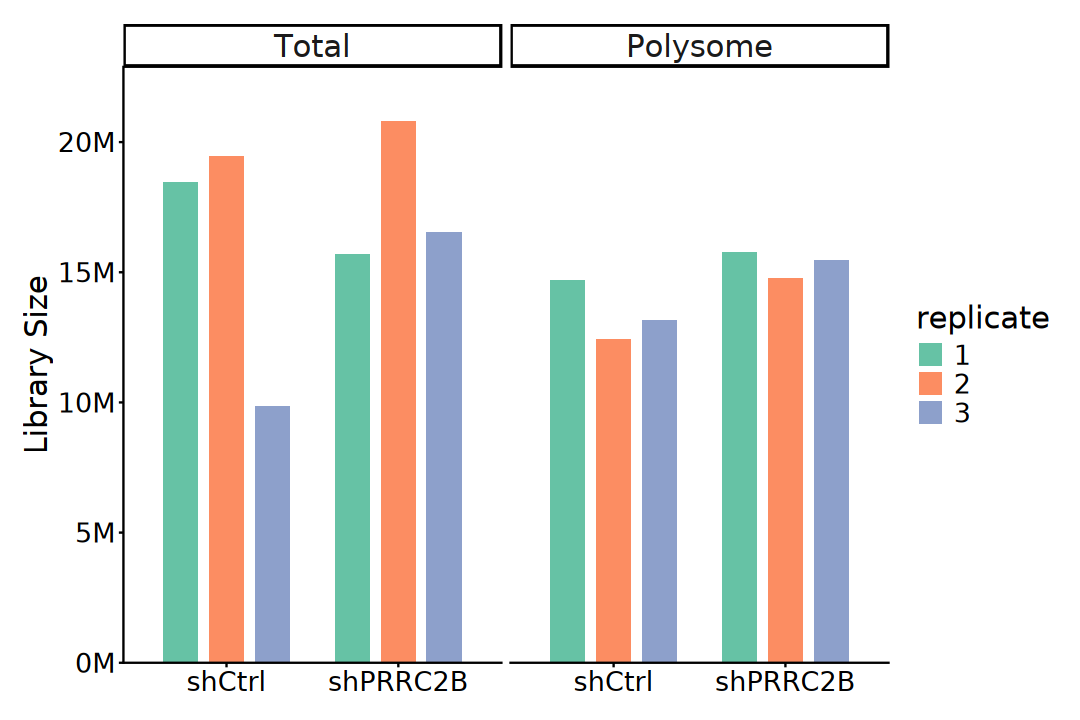

In [58]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = condition, y = librarySize, group = replicate)) +
    geom_bar(
        aes(fill = replicate), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    facet_wrap(~ fraction, nrow = 1) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 2). PCA

In [59]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 1000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [60]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(dds_tmp), by = "row.names")

In [61]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = condition, shape = replicate), size = 5) +
    facet_wrap( ~ fraction, nrow = 1, scales = "free") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [62]:
pca_res <- plotPCA(
    rld_tmp, intgroup = c("condition", "fraction", "replicate"), 
    ntop = 1000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=1000 top features by variance



In [63]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = condition, shape = fraction), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [64]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(dds_tmp)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(dds_tmp), by = "row.names")

In [65]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = condition, shape = fraction), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

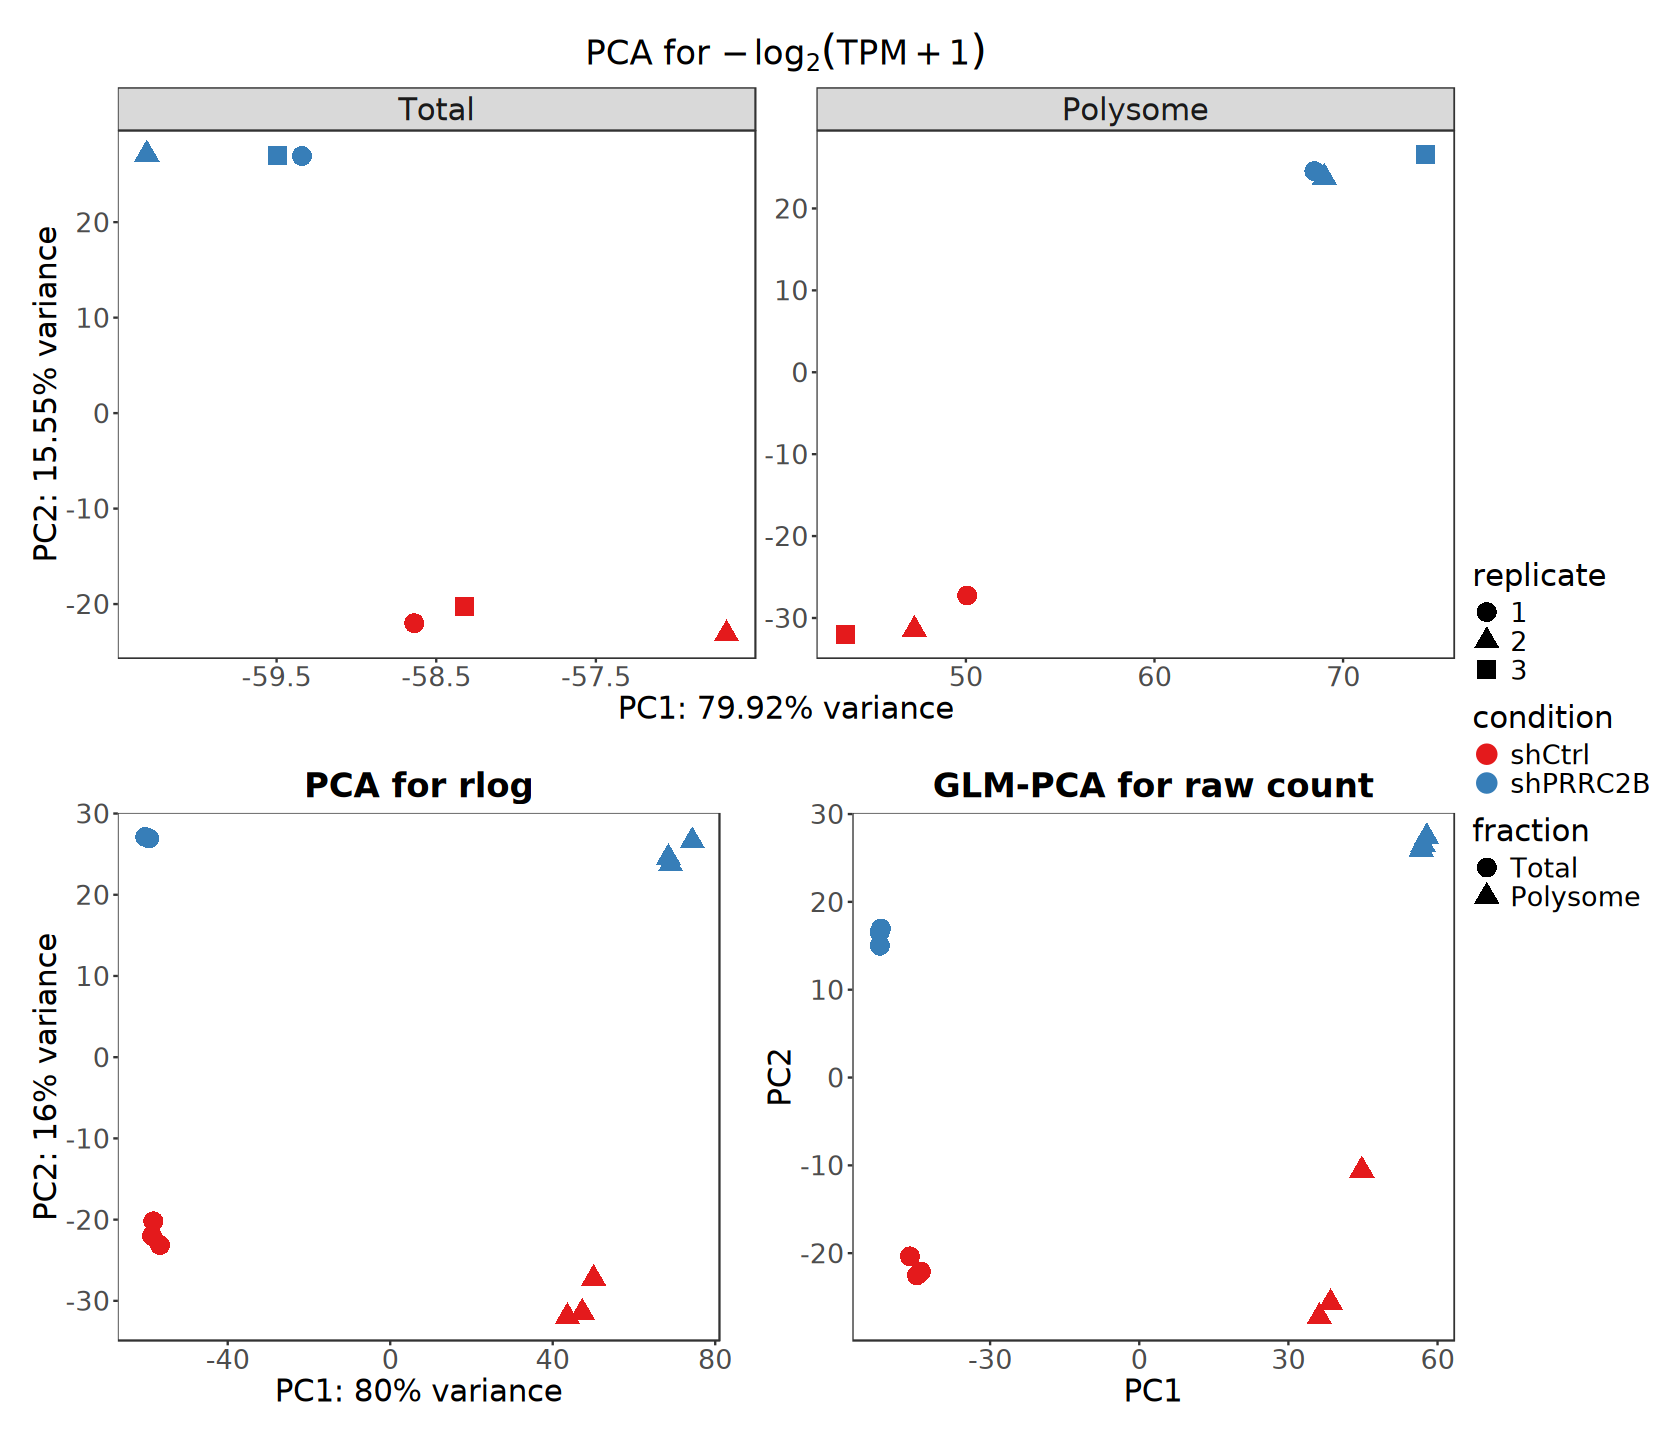

In [66]:
options(repr.plot.width = 14, repr.plot.height = 12)

p1 / (p2 + p3) + plot_layout(nrow = 2, guides = "collect")

## 5). Sample Distance

In [67]:
ac <- colData(dds_tmp) |> as.data.frame() |>
    dplyr::select(replicate, fraction, condition)

In [68]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds_tmp$condition)),
    levels(dds_tmp$condition))
library_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(dds_tmp$fraction)),
    levels(dds_tmp$fraction))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds_tmp$replicate)),
    levels(dds_tmp$replicate))

anno_colors <- list(
    condition = group_colors,
    fraction = library_colors,
    replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [69]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

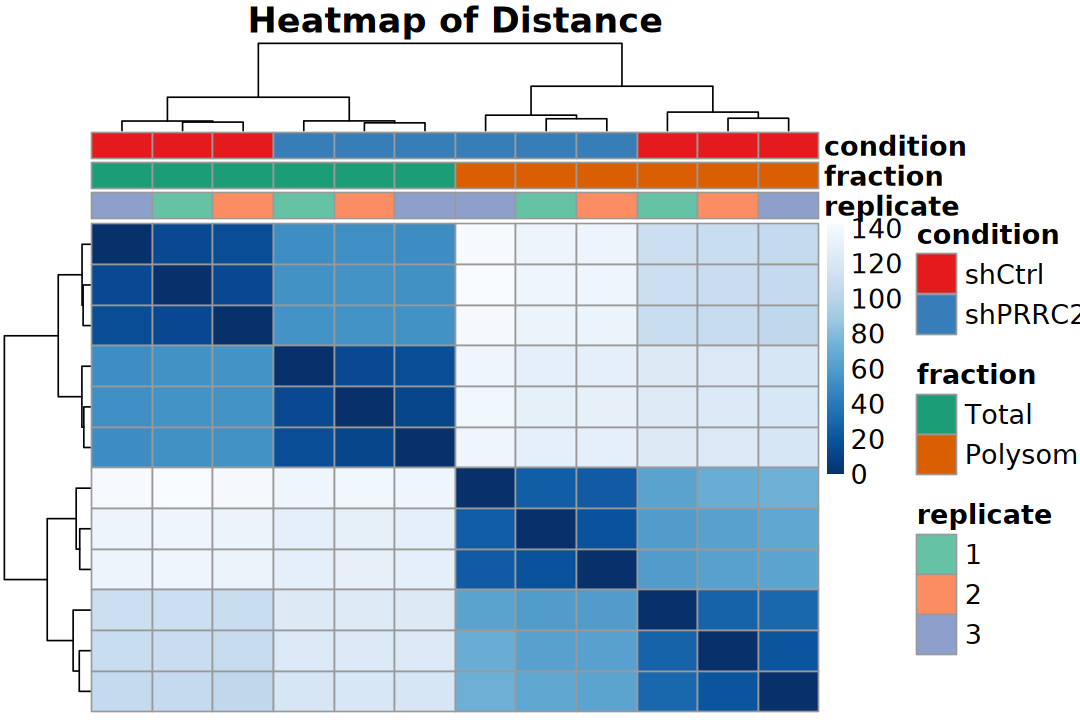

In [70]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [71]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(dds_tmp)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(dds_tmp)

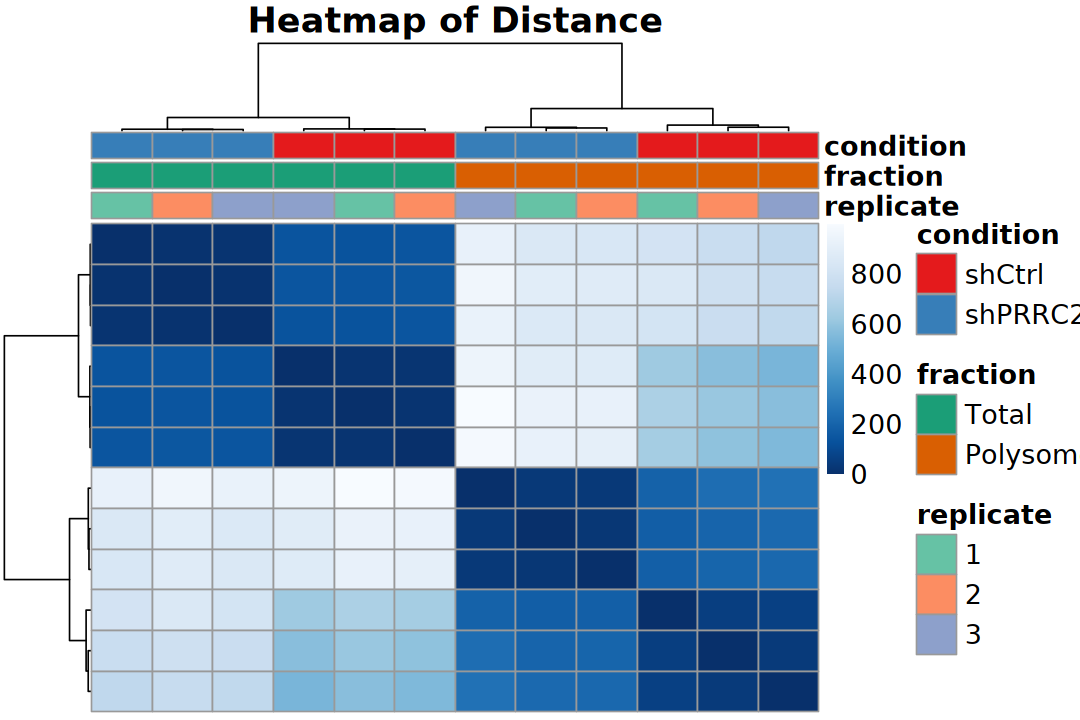

In [72]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [73]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

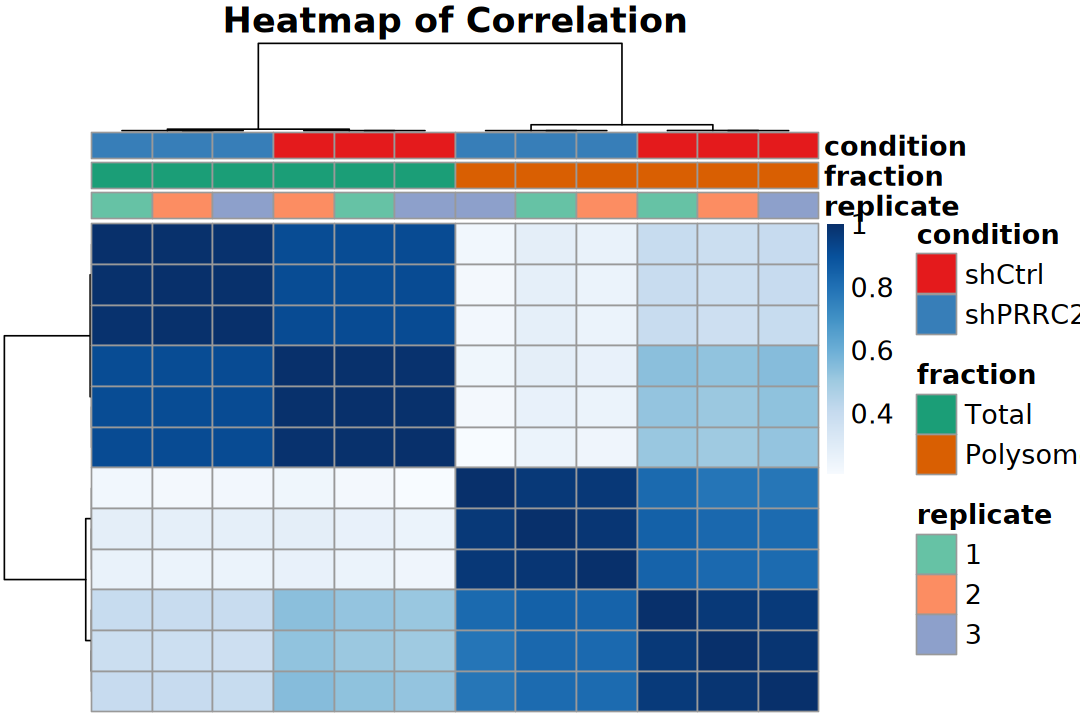

In [74]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

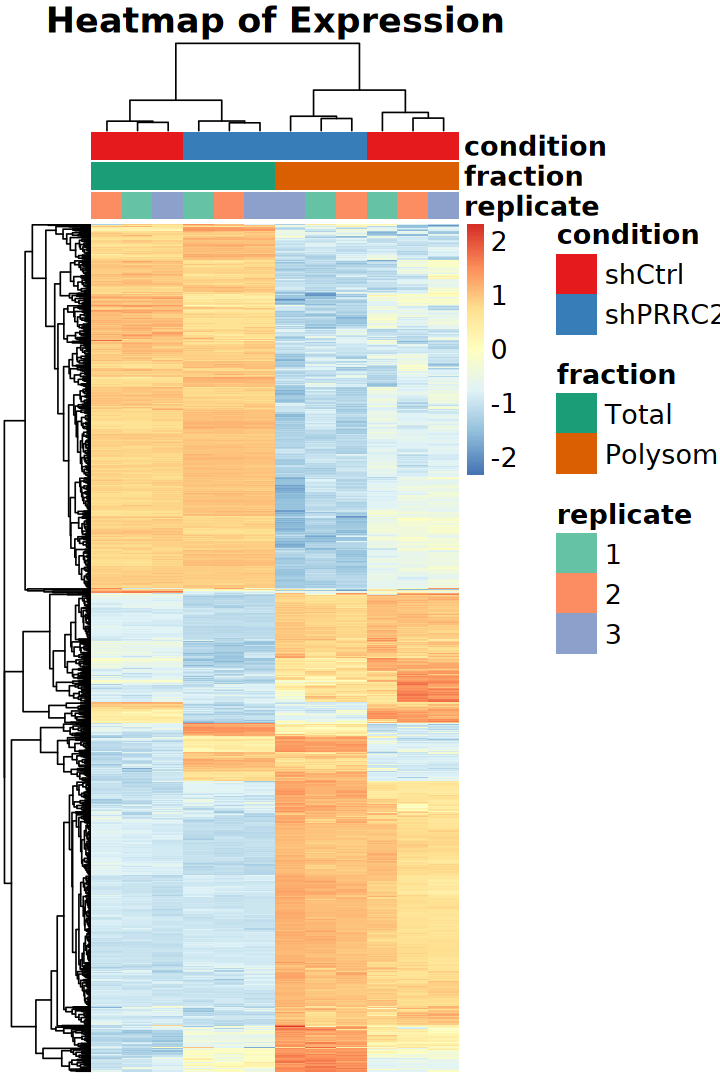

In [75]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

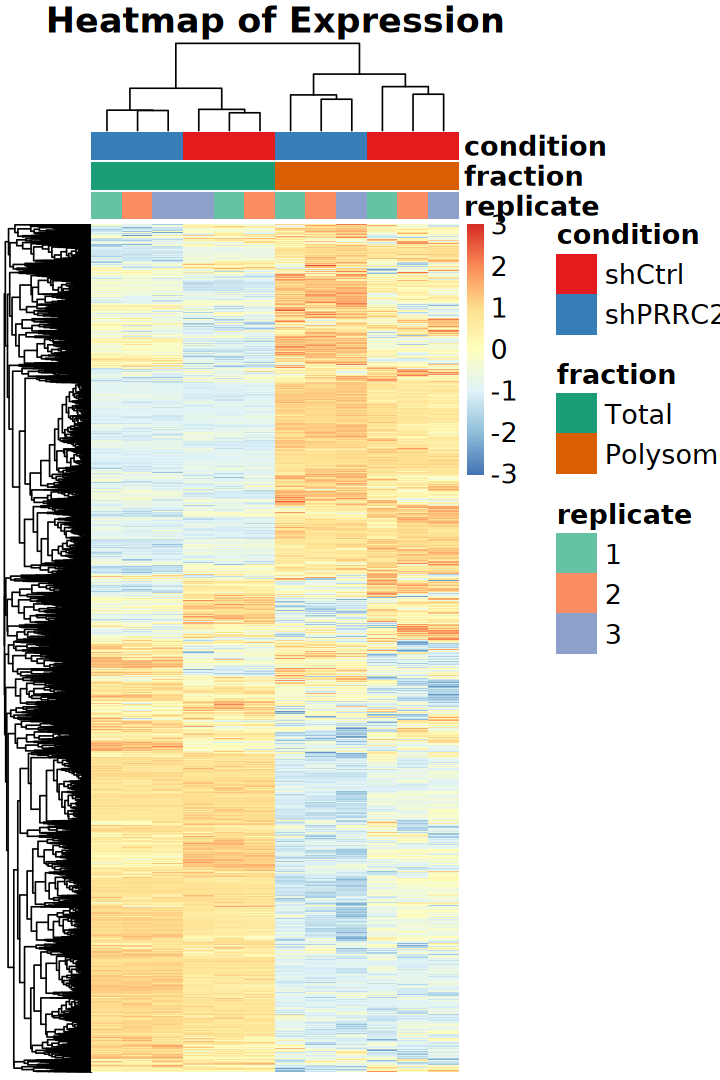

In [76]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat, scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

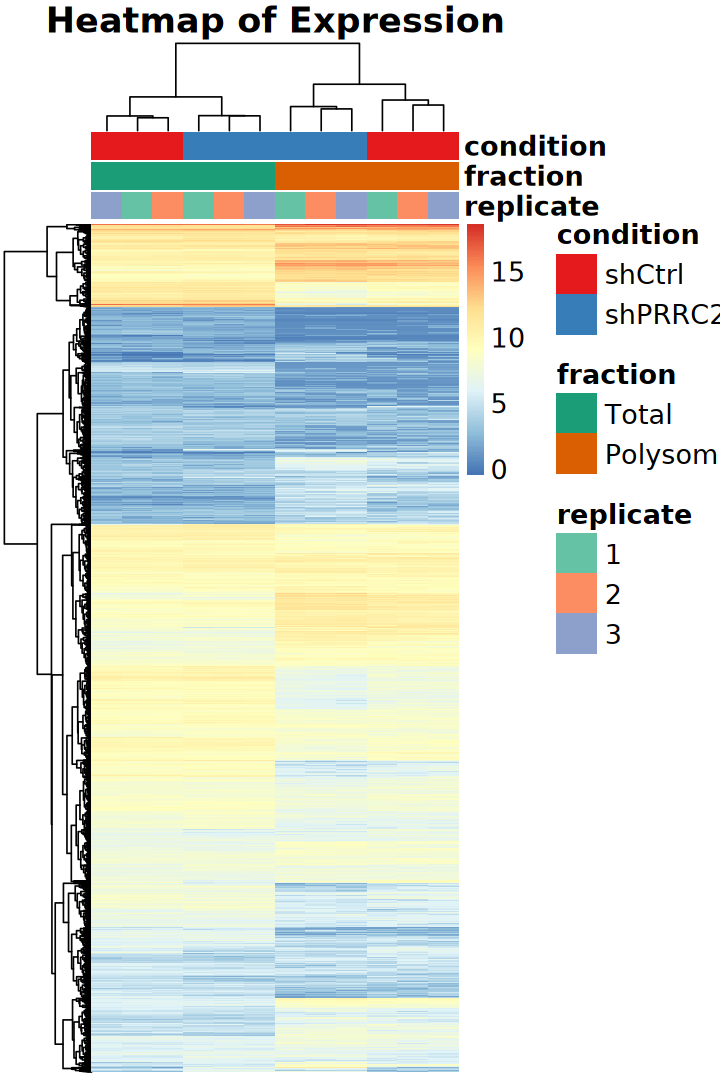

In [77]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat,
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)